# Maximum line speed for the two-layer FEP / HT 2181 coating

This notebook finds the coating design and die temperature that give the highest line speed $V$
without melt fracture, using the multilayer die-land model in `../wirecoating.py`.

**Contents**
1. Problem statement and inputs
2. Method: how the optimum is found
3. Checks that the method is valid (monotonicity, unimodality, FEP thickness)
4. Results: optimum design, temperature sweep, single-layer comparison
5. Profiles at the optimum
6. Wall shear stress against line speed (how it is computed; monotonicity)

## 1. Problem

| Quantity | Value | Source |
|---|---|---|
| Wire radius $R_w$ | 0.577 mm / 2 | Table II |
| Die-land radius $R_d$ | 1.25 mm / 2 | Table II |
| Land length $L$ | 0.10 mm | Table II |
| FEP 9835 thickness (room temperature) | $t_F \ge 0.20$ mm | Table II |
| Total thickness (room temperature) | $t_F + t_H \le 0.25$ mm | Table II |
| Die temperature | $285\ \text{°C} \le T \le 330\ \text{°C}$ | HT data from 285 °C; 330 °C degradation limit |
| Melt fracture | $\max\lvert\tau\rvert$ at each wall $\le \tau_c = 2\times10^5$ Pa | Table I |
| Draw-down (molten) | DDR $\le 2$ | project text |

Layers are listed from the wire outward: FEP inside, HT 2181 outside.

**Model** (see `wirecoating.py`). The flow in the land is fully developed and isothermal, with $\tau(r) = -Gr/2 + C/r$.
Each layer follows a Cross model with an Arrhenius time–temperature shift
$\eta(\dot\gamma;T) = a_T\,\eta_\text{ref}(a_T\dot\gamma)$, where $a_T = \exp[E_a/R\,(1/T - 1/T_\text{ref})]$.
The boundary conditions are no slip at the wire ($u = V$) and at the die wall ($u = 0$).
Mass conservation links each layer's melt flow to its room-temperature thickness:
$Q_k = (\rho_{s}/\rho_{m})_k\,V\,\pi(r_k^2 - r_{k-1}^2)$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from scipy.optimize import brentq, minimize_scalar

sys.path.insert(0, str(Path("..").resolve()))
from wirecoating import WireCoatingDie, CrossLayer

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(fig, name, **kwargs):
    # Write the figure as PNG and PDF.
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=600, bbox_inches="tight", **kwargs)

In [2]:
K0 = 273.15
R_W, R_D, L_LAND = 0.577e-3 / 2, 1.25e-3 / 2, 0.10e-3
TAU_C = 2e5                       # critical wall shear stress [Pa]
T_FEP_MIN, T_TOTAL_MAX = 0.20e-3, 0.25e-3
T_MIN, T_MAX = 285 + K0, 330 + K0
DDR_MAX = 2.0

# Cross parameters from ../trios data/cross_model_parameters.csv
FEP = CrossLayer(eta0=3044, lam=0.0103, m=0.685, E_a=51.4e3, T_ref=330 + K0,
                 name="FEP 9835", rho_melt=1400, rho_solid=2100)
HT = CrossLayer(eta0=12780, lam=1.0345, m=0.529, E_a=92.7e3, T_ref=300 + K0,
                name="HT 2181", rho_melt=1400, rho_solid=1700)

pd.DataFrame(
    [[l.name, l.eta0, l.lam, l.m, l.E_a / 1e3, l.T_ref - K0, l.rho_melt, l.rho_solid] for l in (FEP, HT)],
    columns=["polymer", "η0 [Pa s]", "λ [s]", "m", "E_a [kJ/mol]", "T_ref [°C]", "ρ_melt", "ρ_solid"],
).set_index("polymer")

,η0 [Pa s],λ [s],m,E_a [kJ/mol],T_ref [°C],ρ_melt,ρ_solid
polymer,,,,,,,
FEP 9835,3044,0.0103,0.685,51.4,330,1400,2100
HT 2181,12780,1.034,0.529,92.7,300,1400,1700


## 2. Method

The design variables are the HT thickness $t_H$ and the die temperature $T$, with $t_F$ fixed at 0.20 mm.
Section 3 checks that a thicker FEP layer never helps. The search is split into three nested levels.

**Inner level: the flow at a given speed.** `WireCoatingDie.solve` takes $V$, the thicknesses and $T$.
It solves the $N+1$ nonlinear equations for the two wall stresses and the interface radius. These are
the flow rate of each layer and $u(R_d) = 0$, solved with trust-region least squares (`scipy.optimize.least_squares`).

**Middle level: the speed limit $V^*(t_H, T)$.** Because $Q_k \propto V$, the only effect of $V$ is to set
how hard the melt is sheared. Define

$$g(V) = \frac{\max(\lvert\tau_w\rvert, \lvert\tau_d\rvert)}{\tau_c} - 1 .$$

$\lvert\tau\rvert$ has no interior maximum in the annulus, so the wall maximum is the maximum anywhere in either layer.
$g$ increases monotonically with $V$ (checked in Section 3). So $V^*$ is its single root, found with
**Brent's method** (`brentq`) on $\ln V \in [\ln 10^{-4}, \ln 20]$. Every solve after the first is
warm-started from the previous solution.

**Outer level: the best design.**
* For each $T$, $V^*(t_H)$ is maximised over $0 < t_H \le 0.25 - t_F$ with **Brent's bounded scalar
  minimisation** (`minimize_scalar(method="bounded")`). This relies on $V^*(t_H)$ having a single peak, which a grid scan confirms in Section 3.
* $T$ is scanned on a grid from 285 to 330 °C. $V^*$ rises monotonically with $T$, so the optimum is at the 330 °C limit.

**Constraints after the optimum is found.** DDR $\le 2$, and the room-temperature thicknesses recomputed from the solved flow rates
must match the requested ones.

In [3]:
def make_die(V, layers=(FEP, HT)):
    return WireCoatingDie(R_W, R_D, V, list(layers), L=L_LAND)


def max_wall_stress(sol):
    return max(abs(sol.tau_wire), abs(sol.tau_die))


def speed_limit(thicknesses, T, layers=(FEP, HT)):
    # Line speed V* [m/s] at which the larger wall shear stress equals TAU_C.
    # Returns (V*, solution at V*).
    state = {"warm": None, "sol": {}}

    def g(lnV):
        sol = make_die(np.exp(lnV), layers).solve(thicknesses=thicknesses, T=T, warm_start=state["warm"])
        state["warm"] = sol
        state["sol"][lnV] = sol
        return max_wall_stress(sol) / TAU_C - 1.0

    lnV = brentq(g, np.log(1e-4), np.log(20.0), xtol=1e-10)
    return float(np.exp(lnV)), state["sol"][lnV]


def best_ht(T, t_fep=T_FEP_MIN):
    # Maximise V* over the HT thickness at temperature T (Brent bounded).
    upper = T_TOTAL_MAX - t_fep
    res = minimize_scalar(lambda x: -speed_limit([t_fep, x * 1e-3], T)[0],
                          bounds=(0.002, upper * 1e3), method="bounded", options={"xatol": 1e-5})
    return res.x * 1e-3, -res.fun

## 3. Checks on the method

**3a. $g(V)$ is monotonic.** If it weren't, `brentq` could return a root that isn't the first crossing.

In [4]:
V_grid = np.geomspace(1e-3, 1.0, 25)
gm = [max_wall_stress(make_die(V).solve(thicknesses=[0.20e-3, 0.03e-3], T=T_MAX)) for V in V_grid]
print("max wall stress increases monotonically with V:", bool(np.all(np.diff(gm) > 0)))

max wall stress increases monotonically with V: True


**3b. $V^*(t_H)$ has a single peak** at every temperature, so a bounded 1-D search finds the global optimum.

In [5]:
t_grid = np.linspace(0.002, 0.050, 25) * 1e-3 * 1e3   # mm
T_scan = [285, 300, 315, 330]
scan = pd.DataFrame(
    {f"{Tc} °C": [speed_limit([T_FEP_MIN, t * 1e-3], Tc + K0)[0] for t in t_grid] for Tc in T_scan},
    index=pd.Index(np.round(t_grid, 4), name="t_HT [mm]"))
for col in scan:
    dv = np.sign(np.diff(scan[col].values))
    print(f"{col}: sign changes in dV*/dt_HT = {int(np.sum(dv[1:] != dv[:-1]))} (1 = single peak)")

285 °C: sign changes in dV*/dt_HT = 1 (1 = single peak)
300 °C: sign changes in dV*/dt_HT = 1 (1 = single peak)
315 °C: sign changes in dV*/dt_HT = 1 (1 = single peak)
330 °C: sign changes in dV*/dt_HT = 1 (1 = single peak)


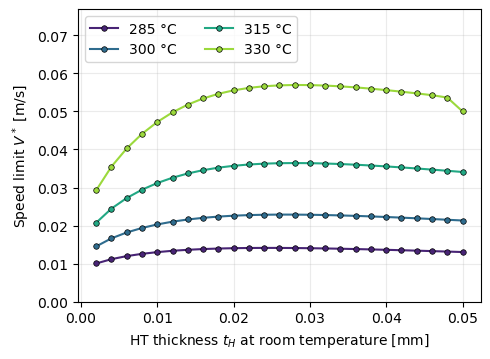

In [6]:
colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(T_scan)))
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for c, col in zip(colors, scan):
    ax.plot(scan.index, scan[col], "-o", color=c, ms=4, mec="k", mew=0.5, label=col)
ax.set_xlabel(r"HT thickness $t_H$ at room temperature [mm]")
ax.set_ylabel(r"Speed limit $V^*$ [m/s]")
ax.set_ylim(0, scan.values.max() * 1.35)
ax.legend(loc="upper left", ncol=2, frameon=True)
ax.grid(alpha=0.25)
save_fig(fig, "vstar_vs_tHT")
plt.show()

**3c. Thicker FEP doesn't help.** With $t_H$ re-optimised each time, $V^*$ drops as $t_F$ rises above 0.20 mm.
So the $t_F \ge 0.20$ mm constraint is active.

In [7]:
rows = []
for tf in [0.200, 0.210, 0.220, 0.230]:
    th, V = best_ht(T_MAX, t_fep=tf * 1e-3)
    rows.append([tf, th * 1e3, V])
pd.DataFrame(rows, columns=["t_FEP [mm]", "best t_HT [mm]", "V* [m/s]"]).set_index("t_FEP [mm]")

,best t_HT [mm],V* [m/s]
t_FEP [mm],,
0.2,0.02852,0.05696
0.21,0.03202,0.05055
0.22,0.02999,0.04551
0.23,0.02,0.03908


## 4. Results

**4a. Temperature sweep.** The HT thickness is re-optimised at each temperature. The last two columns give FEP alone (0.20 mm) for comparison.

In [8]:
rows = []
for Tc in np.arange(285, 331, 5):
    T = Tc + K0
    th, V = best_ht(T)
    _, sol = speed_limit([T_FEP_MIN, th], T)
    V1, _ = speed_limit([T_FEP_MIN], T, layers=(FEP,))
    rows.append(dict(T_C=Tc, t_HT_mm=th * 1e3, V_star=V, V_star_mpm=V * 60,
                     tau_wire=sol.tau_wire, tau_die=sol.tau_die, DDR=sol.draw_down_ratio,
                     V_FEP_only=V1, gain=V / V1))
sweep = pd.DataFrame(rows).set_index("T_C")
sweep.columns = ["t_HT [mm]", "V* [m/s]", "V* [m/min]", "τ_wire [Pa]", "τ_die [Pa]", "DDR",
                 "V* FEP only [m/s]", "gain vs FEP only"]
sweep

,t_HT [mm],V* [m/s],V* [m/min],τ_wire [Pa],τ_die [Pa],DDR,V* FEP only [m/s],gain vs FEP only
T_C,,,,,,,,
285,0.02454,0.01414,0.8486,1.019e+05,-2e+05,1.169,0.007211,1.961
290,0.02541,0.01664,0.9983,1.032e+05,-2e+05,1.164,0.007956,2.091
295,0.02616,0.01954,1.172,1.043e+05,-2e+05,1.16,0.008763,2.23
300,0.02678,0.0229,1.374,1.053e+05,-2e+05,1.157,0.009636,2.377
305,0.02729,0.02679,1.607,1.06e+05,-2e+05,1.154,0.01058,2.533
310,0.02771,0.03128,1.877,1.065e+05,-2e+05,1.152,0.01159,2.698
315,0.02803,0.03644,2.186,1.067e+05,-2e+05,1.15,0.01269,2.872
320,0.02827,0.04237,2.542,1.066e+05,-2e+05,1.149,0.01386,3.057
325,0.02843,0.04918,2.951,1.061e+05,-2e+05,1.148,0.01512,3.251


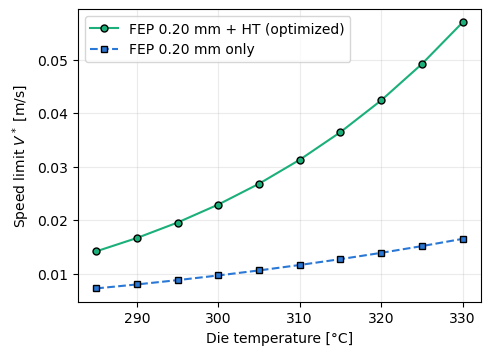

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.plot(sweep.index, sweep["V* [m/s]"], "-o", color="#1baf7a", mec="k", ms=5, label="FEP 0.20 mm + HT (optimized)")
ax.plot(sweep.index, sweep["V* FEP only [m/s]"], "--s", color="#2a78d6", mec="k", ms=5, label="FEP 0.20 mm only")
ax.set_xlabel("Die temperature [°C]")
ax.set_ylabel(r"Speed limit $V^*$ [m/s]")
ax.legend(loc="upper left", frameon=True)
ax.grid(alpha=0.25)
save_fig(fig, "vstar_vs_T")
plt.show()

**4b. Optimum design.**

In [10]:
T_opt = float(sweep["V* [m/s]"].idxmax()) + K0
t_ht_opt, V_opt = best_ht(T_opt)
_, sol = speed_limit([T_FEP_MIN, t_ht_opt], T_opt)
die = sol.die

summary = pd.Series({
    "die temperature [°C]": T_opt - K0,
    "FEP thickness (RT) [mm]": T_FEP_MIN * 1e3,
    "HT thickness (RT) [mm]": t_ht_opt * 1e3,
    "total thickness (RT) [mm]": (T_FEP_MIN + t_ht_opt) * 1e3,
    "line speed V* [m/s]": V_opt,
    "line speed V* [m/min]": V_opt * 60,
    "wire shear stress [Pa]": sol.tau_wire,
    "die-wall shear stress [Pa]": sol.tau_die,
    "pressure drop over land [MPa]": sol.pressure_drop / 1e6,
    "draw-down ratio": sol.draw_down_ratio,
    "solver residual": sol.residual,
}, name="optimum")
summary.to_frame()

,optimum
die temperature [°C],330
FEP thickness (RT) [mm],0.2
HT thickness (RT) [mm],0.02852
total thickness (RT) [mm],0.2285
line speed V* [m/s],0.05696
line speed V* [m/min],3.417
wire shear stress [Pa],1.052e+05
die-wall shear stress [Pa],-2e+05
pressure drop over land [MPa],0.1011
draw-down ratio,1.147


In [11]:
layer_table = pd.DataFrame({
    "Q [mm³/s]": sol.Q * 1e9,
    "land thickness [mm]": np.diff(sol.radii) * 1e3,
    "max |τ| in layer [Pa]": sol.layer_max_stress,
    "molten thickness [mm]": sol.molten_thicknesses * 1e3,
    "RT thickness [mm]": sol.final_thicknesses * 1e3,
}, index=[l.name for l in die.layers])
layer_table

,Q [mm³/s],land thickness [mm],max |τ| in layer [Pa],molten thickness [mm],RT thickness [mm]
FEP 9835,41.71,0.2745,1.559e+05,0.2739,0.2
HT 2181,6.231,0.062,2e+05,0.03015,0.02852


**4c. Constraint check at the optimum.**

In [12]:
checks = pd.DataFrame([
    ["FEP thickness ≥ 0.20 mm", sol.final_thicknesses[0] * 1e3, ">= 0.20", sol.final_thicknesses[0] >= T_FEP_MIN - 1e-12],
    ["total thickness ≤ 0.25 mm", sol.final_thicknesses.sum() * 1e3, "<= 0.25", sol.final_thicknesses.sum() <= T_TOTAL_MAX + 1e-12],
    ["max wall |τ| ≤ τ_c", max_wall_stress(sol), "<= 2e5", max_wall_stress(sol) <= TAU_C * (1 + 1e-9)],
    ["draw-down ≤ 2", sol.draw_down_ratio, "<= 2", sol.draw_down_ratio <= DDR_MAX],
    ["285 ≤ T ≤ 330 °C", T_opt - K0, "[285, 330]", T_MIN <= T_opt <= T_MAX],
    ["flow-rate residual", float(np.max(np.abs(sol.Q_calc / sol.Q - 1))), "~0", float(np.max(np.abs(sol.Q_calc / sol.Q - 1))) < 1e-10],
], columns=["constraint", "value", "limit", "satisfied"]).set_index("constraint")
checks

,value,limit,satisfied
constraint,,,
FEP thickness ≥ 0.20 mm,0.2,>= 0.20,True
total thickness ≤ 0.25 mm,0.2285,<= 0.25,True
max wall |τ| ≤ τ_c,2e+05,<= 2e5,True
draw-down ≤ 2,1.147,<= 2,True
285 ≤ T ≤ 330 °C,330,"[285, 330]",True
flow-rate residual,2.22e-16,~0,True


## 5. Profiles at the optimum

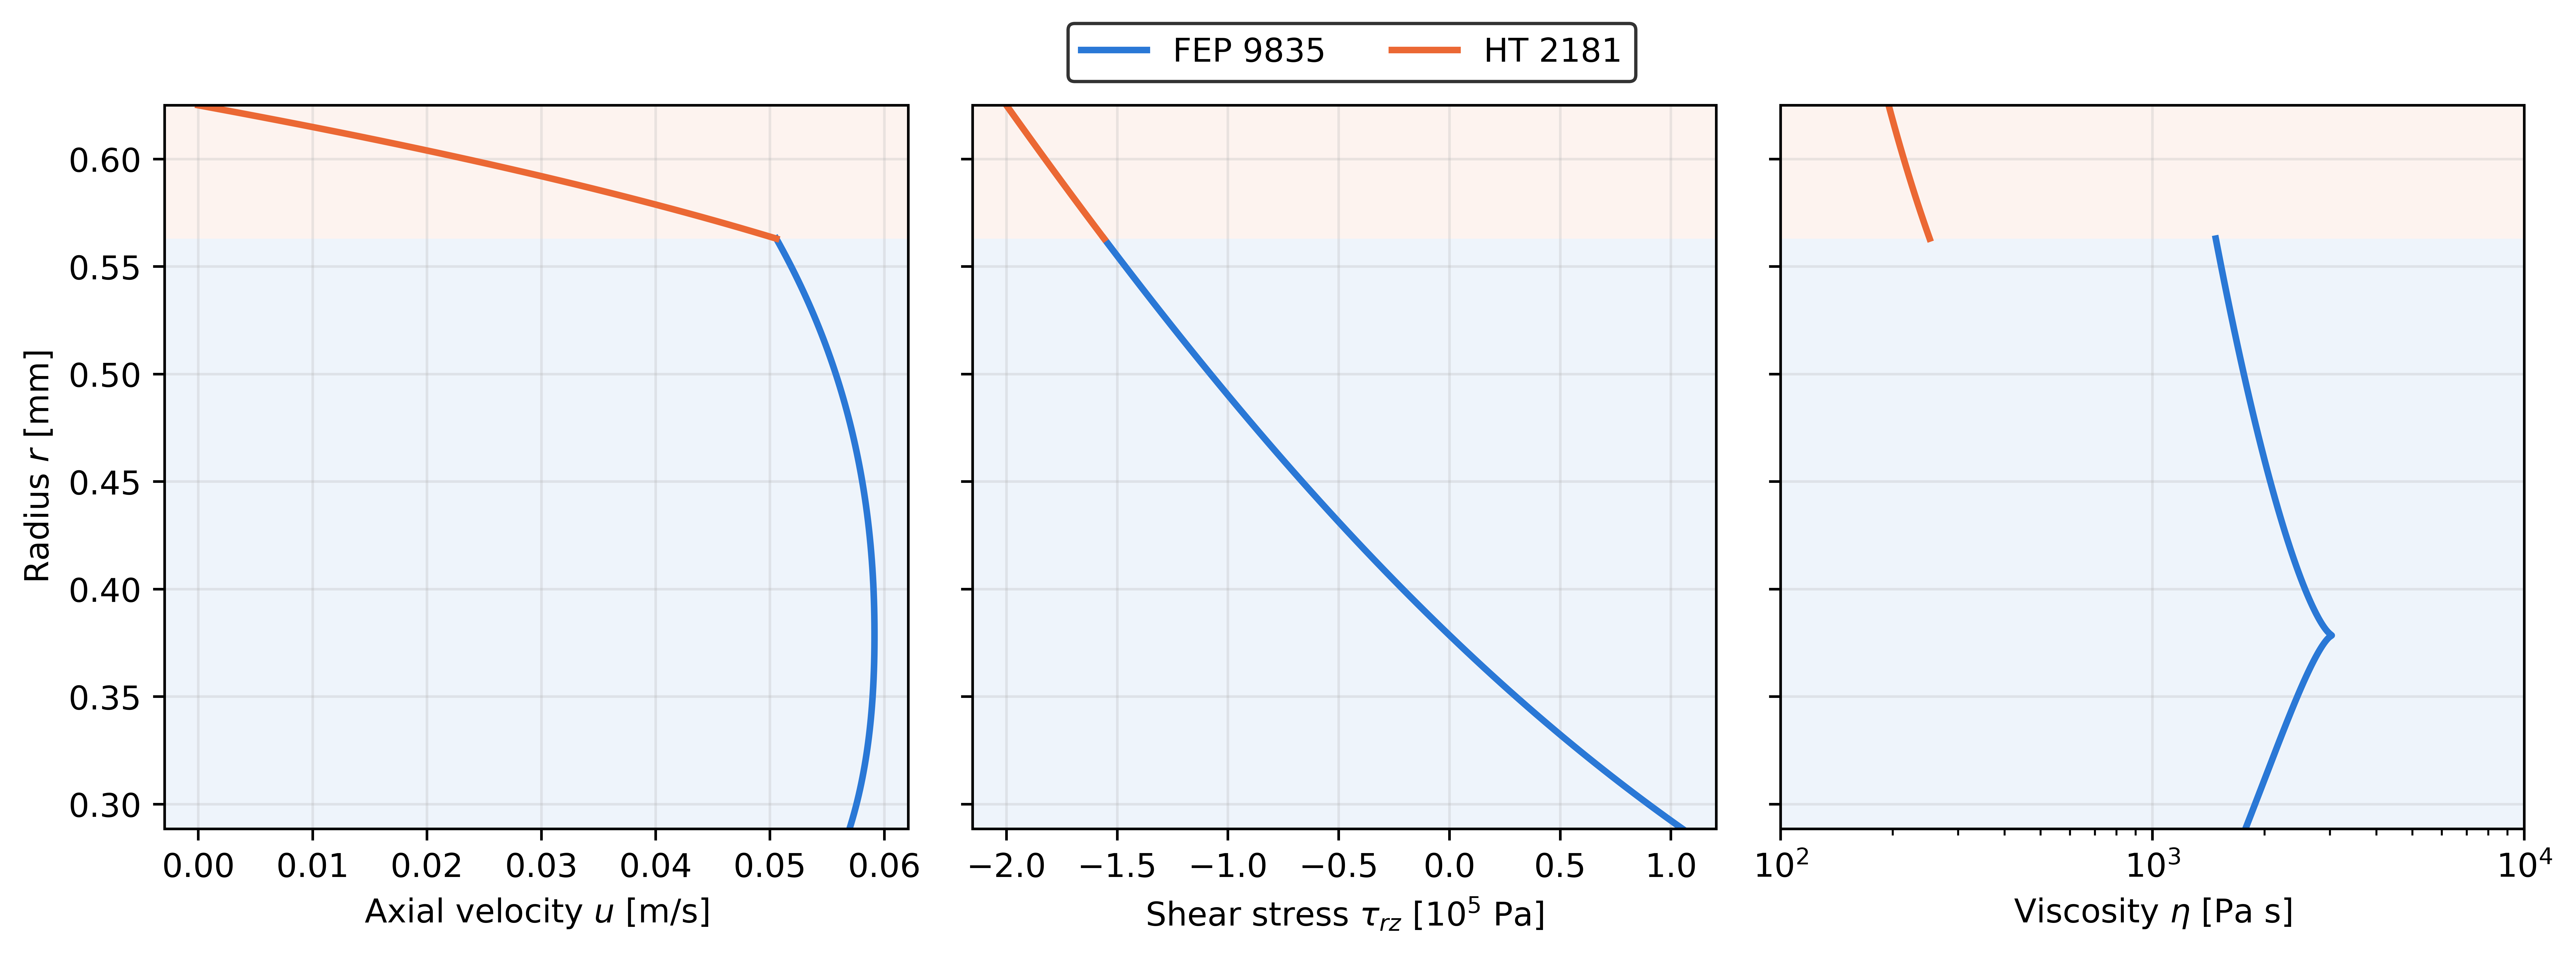

In [13]:
from wirecoating import LAYER_COLORS
prof = die.profiles(sol, 300)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True, dpi=900)
for i, (p, layer) in enumerate(zip(prof, die.layers)):
    r = p["r"] * 1e3
    axes[0].plot(p["u"], r, color=LAYER_COLORS[i], lw=2, label=layer.name)
    axes[1].plot(p["tau"] / 1e5, r, color=LAYER_COLORS[i], lw=2)
    axes[2].plot(p["eta"], r, color=LAYER_COLORS[i], lw=2)
for ax in axes:
    for i in range(die.n_layers):          # shade each layer's band in the land
        ax.axhspan(sol.radii[i] * 1e3, sol.radii[i + 1] * 1e3, color=LAYER_COLORS[i], alpha=0.08, lw=0)
    ax.grid(alpha=0.25)
    ax.set_ylim(R_W * 1e3, R_D * 1e3)
axes[0].set_xlabel("Axial velocity $u$ [m/s]")
axes[0].set_ylabel("Radius $r$ [mm]")
axes[1].set_xlabel(r"Shear stress $\tau_{rz}$ [$10^5$ Pa]")
axes[2].set_xlabel(r"Viscosity $\eta$ [Pa s]")
axes[2].set_xscale("log")
axes[2].set_xlim(1e2, 1e4)
axes[2].xaxis.set_major_locator(LogLocator(base=10.0, subs=(1.0,)))
axes[2].xaxis.set_minor_formatter(NullFormatter())
fig.legend(bbox_to_anchor=(0.64,1.07), frameon=True, edgecolor='black', ncol=2)
fig.tight_layout()
save_fig(fig, "profiles_at_optimum")
plt.show()

## Notes and limitations

* At the optimum the limiting constraint is melt fracture at the **die wall**, in the HT layer. The wire stress is about half the limit.
  This is why extra HT helps only up to a point. More HT means more melt flow through a full land, which means a stronger pressure flow and more
  stress at the die wall. That trade-off produces the interior optimum in $t_H$.
* At 330 °C the $V^*(t_H)$ curve drops sharply above about 0.048 mm. There the limiting wall switches from the die (HT) to the wire (FEP),
  because the stronger pressure flow pushes the wire stress up to $\tau_c$. This is a change in the active constraint, not a solver problem.
* The draw-down ratio is about 1.15, well under the limit of 2, so that constraint is inactive. With the land full, DDR is fixed by the thicknesses and doesn't depend on $V$.
* HT rheology at 330 °C is extrapolated: the HT data stop at 315 °C, and the Arrhenius fit carries it the rest of the way. If the brief is read as "don't exceed the
  highest measured temperature of any polymer", use the 315 °C row of the sweep table.
* The model assumes fully developed flow, but the land is short ($L/h \approx 0.3$). Die swell is neglected.

## 6. Wall shear stress against line speed

### How the wall shear stress is computed

**Momentum balance.** In fully developed annular flow, the axial momentum balance integrates to

$$\tau_{rz}(r) = -\frac{G\,r}{2} + \frac{C}{r}, \qquad G = -\frac{dp}{dz},$$

with $\tau_{rz} = \eta\,du/dr$. $r\,\tau_{rz}$ is continuous across each interface, so $G$ and $C$ are the same in every layer.
They are the only two constants for the whole die.

**Finding $G$ and $C$.** The solver doesn't use $G$ and $C$ directly as unknowns. It uses the two wall stresses $\tau_w = \tau(R_w)$ and
$\tau_d = \tau(R_d)$, plus the interface radius. Writing the momentum balance at both walls gives two linear equations, which
`G_and_C_from_wall_stresses` inverts:

$$R_w\tau_w = -\frac{G R_w^2}{2} + C, \qquad R_d\tau_d = -\frac{G R_d^2}{2} + C .$$

For each guess, the solver does the following:
1. Compute $\tau(r)$ everywhere from $G$ and $C$.
2. Invert each layer's Cross law to get $du/dr = \operatorname{sign}(\tau)\,\dot\gamma(\lvert\tau\rvert)$.
3. Integrate outward from $u(R_w) = V$ to get the velocity and each layer's flow rate. The integration uses tanh–sinh quadrature, split at the zero-stress radius.

It then adjusts $(\tau_w, \tau_d, r_1)$ until three equations hold: both layer flow rates equal $(\rho_s/\rho_m)\,V\,A_\text{RT}$, and $u(R_d) = 0$.
The converged $\tau_w$ and $\tau_d$ are the wall shear stresses reported in `sol.tau_wire` and `sol.tau_die`.

**Sign convention.** $\tau > 0$ means $u$ increases with $r$.
* At the optimum $\tau_w > 0$. Next to the wire the melt moves *faster* than the wire, because the pressure flow pushes it ahead.
* $\tau_d < 0$, because the velocity falls to zero at the stationary die wall.

Melt fracture depends on the magnitude, so the constraint is $\max(\lvert\tau_w\rvert, \lvert\tau_d\rvert) \le \tau_c$.

**Why only the walls need checking.** $\tau'' = 2C/r^3$, so $\tau$ is convex if $C > 0$ and concave if $C < 0$. At any interior stationary point,
$\tau'(r_s) = 0$ gives $C = -G r_s^2/2$. Substituting back gives $\tau(r_s) = -G r_s$:
* If $C > 0$, that point is a minimum of $\tau$, and it is positive.
* If $C < 0$, it is a maximum of $\tau$, and it is negative.

In both cases it is a minimum of $\lvert\tau\rvert$. The point where $\tau$ crosses zero is also a minimum of $\lvert\tau\rvert$.
So within any layer, the largest $\lvert\tau\rvert$ is at one of its two boundaries, and over the whole gap it is at one of the two walls.
The stress at an interface is never larger than the larger wall stress.

### Monotonicity in $V$

The method in Section 2 uses a root-finder on $g(V)$, which needs $\max\lvert\tau_\text{wall}\rvert$ to increase monotonically with $V$.
The physics suggests it should. The flow rates scale with $V$, so a higher $V$ shears the same geometry harder, and a Cross fluid's stress
rises monotonically with shear rate. The cell below checks this numerically at the optimum design and temperature. It sweeps $V$ over almost three decades,
from $10^{-3}$ to $0.5$ m/s, and computes the local slope $d\ln\lvert\tau\rvert / d\ln V$.

* A Newtonian fluid would give a slope of exactly 1.
* For these melts the slope is below 1 even at $V = 10^{-3}$ m/s. They are already shear-thinning there: for HT at 330 °C, $\lambda = 0.39$ s.
  As $V$ rises, the slope falls toward the power-law indices $n = 1 - m$ (0.31 for FEP, 0.47 for HT).
* Throughout the sweep it stays well above zero (the table gives the range), so $V^*$ is unique.

In [14]:
V_sweep = np.geomspace(1e-3, 0.5, 40)
tw, td, warm = [], [], None
for V in V_sweep:
    s = make_die(V).solve(thicknesses=[T_FEP_MIN, t_ht_opt], T=T_opt, warm_start=warm)
    warm = s
    tw.append(s.tau_wire)
    td.append(s.tau_die)
tw, td = np.array(tw), np.array(td)
tmax = np.maximum(np.abs(tw), np.abs(td))

wall_table = pd.DataFrame({
    "min slope dln|τ|/dlnV": [np.min(np.diff(np.log(np.abs(x))) / np.diff(np.log(V_sweep))) for x in (tw, td, tmax)],
    "max slope dln|τ|/dlnV": [np.max(np.diff(np.log(np.abs(x))) / np.diff(np.log(V_sweep))) for x in (tw, td, tmax)],
    "sign constant": [bool(np.all(np.sign(x) == np.sign(x[0]))) for x in (tw, td, tmax)],
    "strictly increasing |τ|": [bool(np.all(np.diff(np.abs(x)) > 0)) for x in (tw, td, tmax)],
}, index=["wire  τ_w", "die wall  τ_d", "max wall |τ|"])
wall_table

,min slope dln|τ|/dlnV,max slope dln|τ|/dlnV,sign constant,strictly increasing |τ|
wire τ_w,0.4419,0.6906,True,True
die wall τ_d,0.4803,0.6947,True,True
max wall |τ|,0.4803,0.6947,True,True


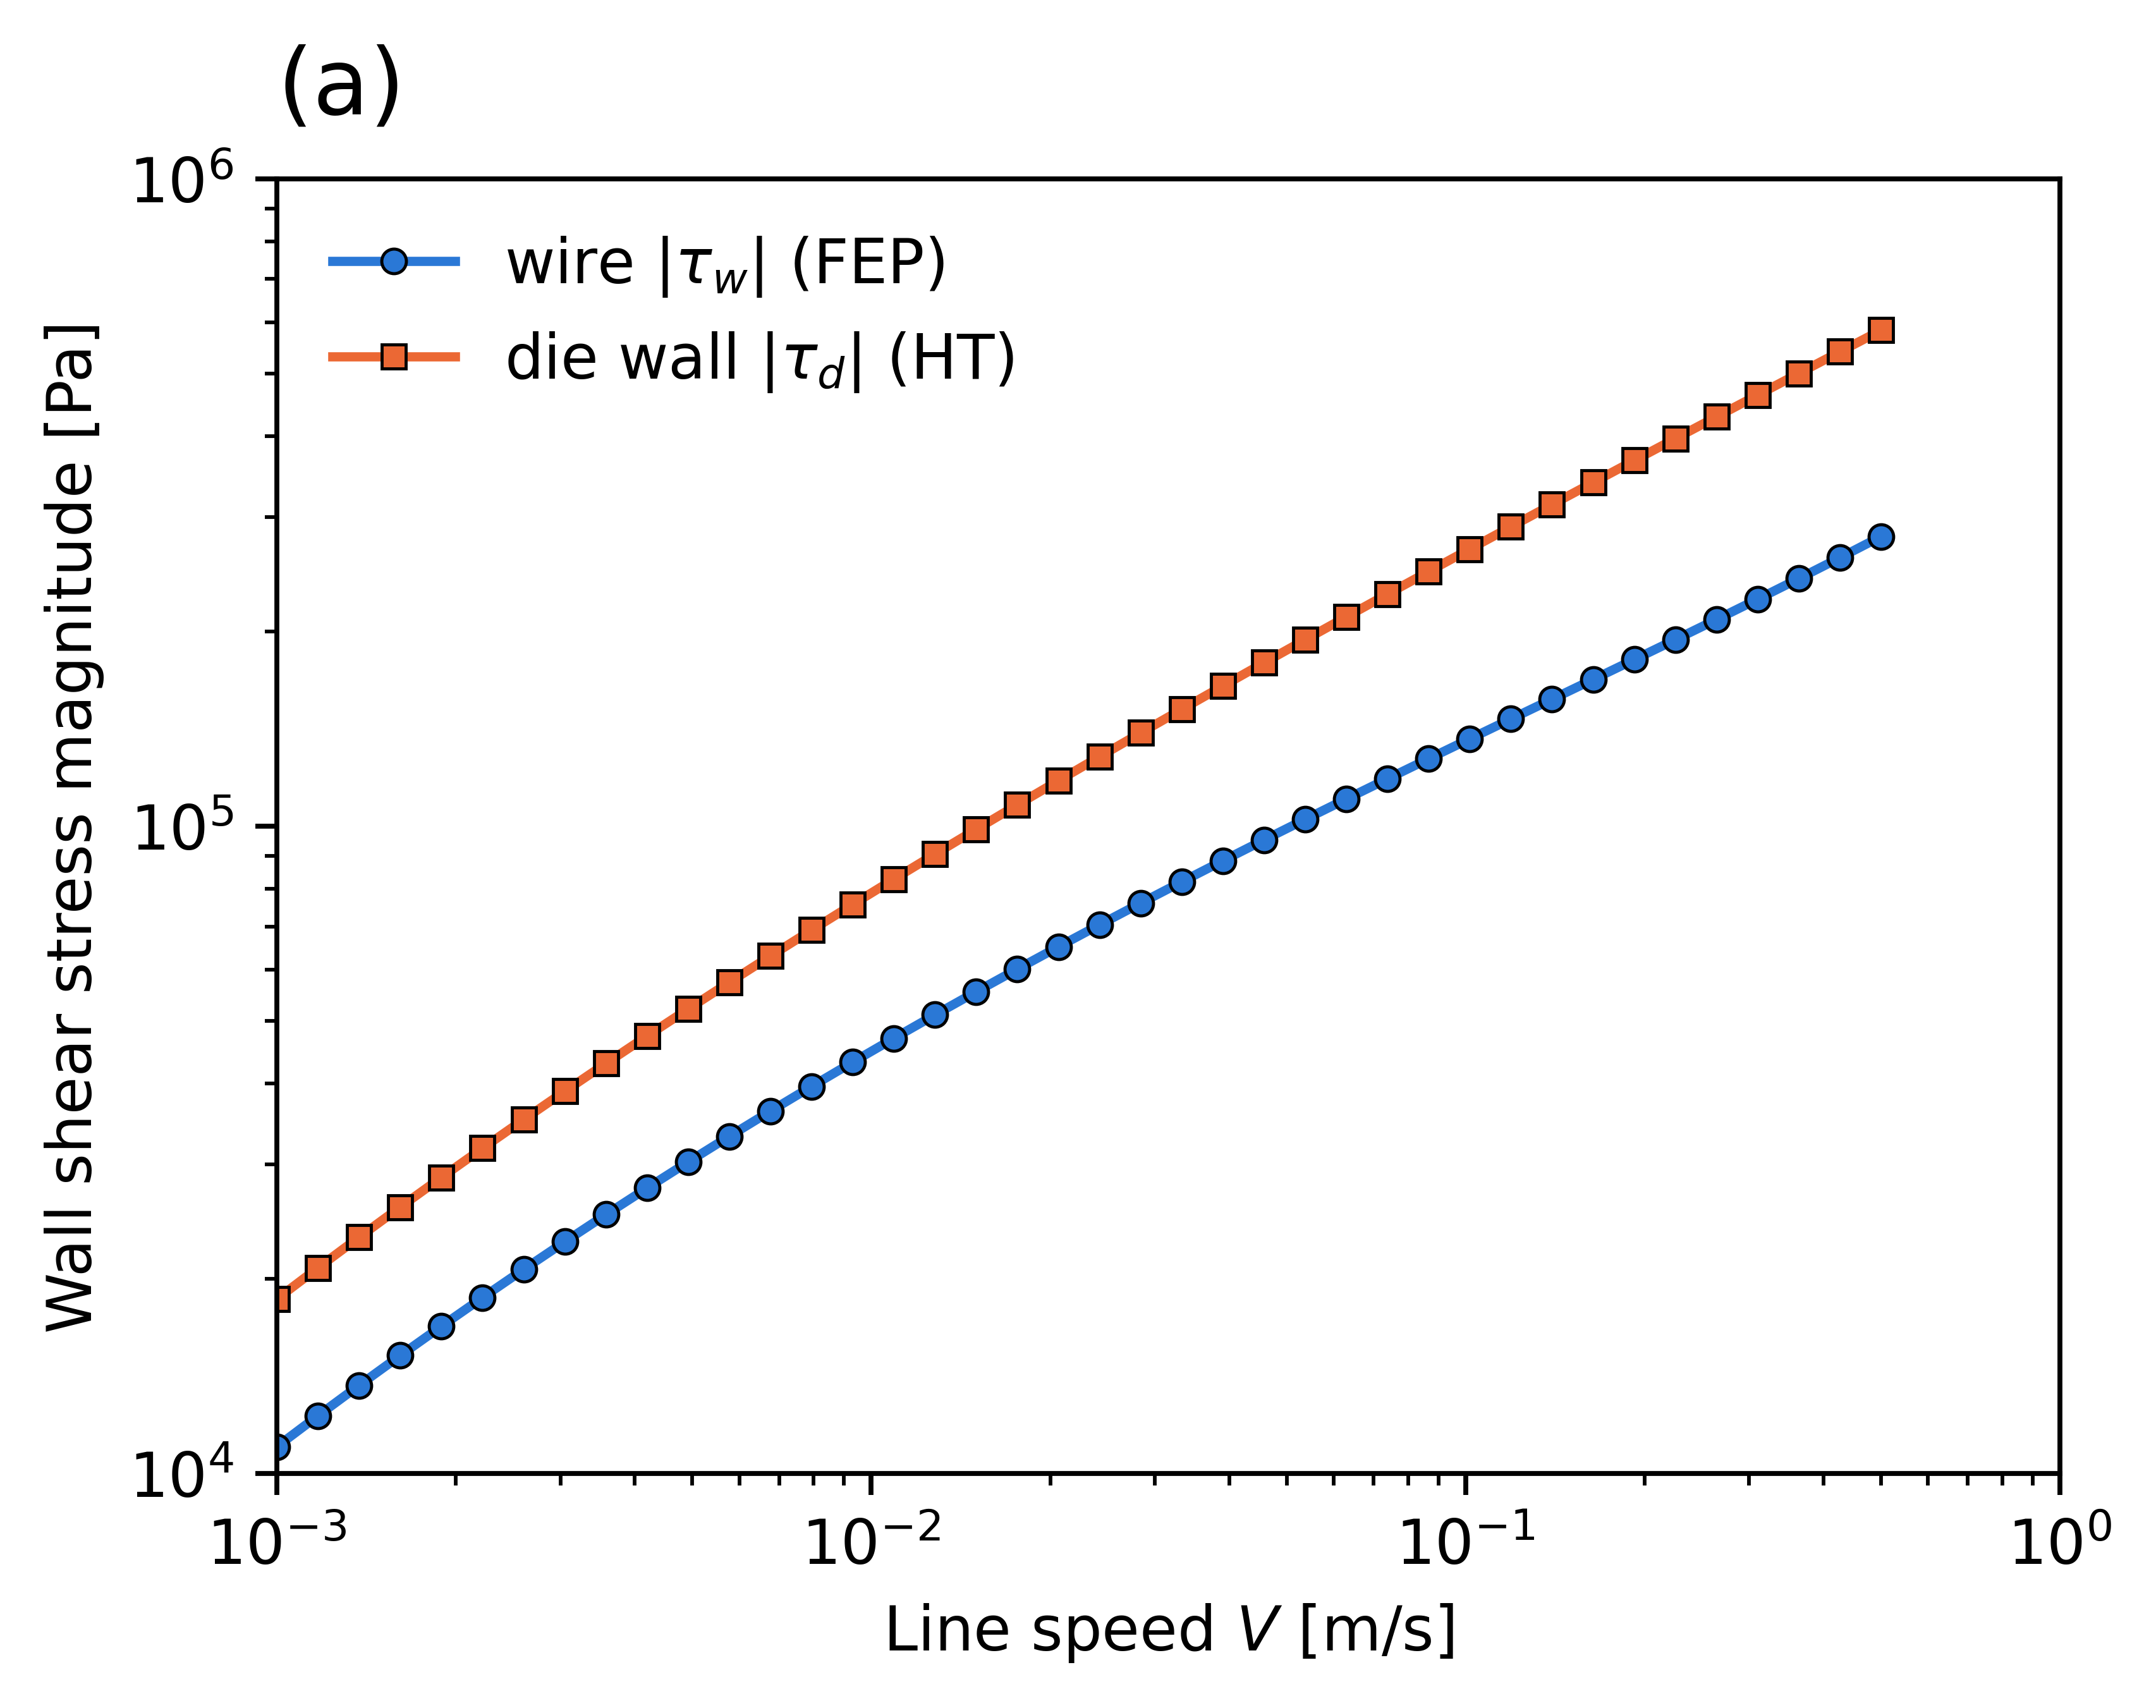

In [15]:
from matplotlib.ticker import LogLocator, NullFormatter
fig, ax = plt.subplots(figsize=(5.2, 3.8), dpi=700)
ax.plot(V_sweep, np.abs(tw), "-o", color=LAYER_COLORS[0], ms=4, mec="k", mew=0.5, label=r"wire $|\tau_w|$ (FEP)")
ax.plot(V_sweep, np.abs(td), "-s", color=LAYER_COLORS[1], ms=4, mec="k", mew=0.5, label=r"die wall $|\tau_d|$ (HT)")
# ax.plot(V_sweep, tmax, "--", color="k", lw=1.2, label=r"$\max(|\tau_w|, |\tau_d|)$")
ax.set_xscale("log")
ax.set_yscale("log")
lo = 10 ** np.floor(np.log10(min(np.abs(tw).min(), np.abs(td).min())))
hi = 10 ** np.ceil(np.log10(tmax.max()))
ax.set_ylim(lo, hi)
ax.set_xlim(1e-3, 1e0)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10.0, subs=(1.0,)))
    axis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"Line speed $V$ [m/s]")
ax.set_ylabel(r"Wall shear stress magnitude [Pa]")
ax.legend(loc="upper left", frameon=False, )
plt.annotate("(a)", (0,1.05), xycoords='axes fraction', fontsize=15)
save_fig(fig, "wall_stress_vs_V")
# plt.show()
# print(f"design: FEP {T_FEP_MIN*1e3:.3f} mm / HT {t_ht_opt*1e3:.4f} mm at {T_opt - K0:.0f} °C; "
    #   f"max wall |τ| reaches τ_c = {TAU_C:.0e} Pa at V* = {V_opt:.5f} m/s")

## 7. Cross model vs power law at the die temperature

The course notebook uses power-law layers. This project uses the Cross model instead. The plot compares the two for both polymers at the optimum
die temperature, so it shows why the change was needed.

* **Solid line:** the Cross fit, shifted to the die temperature with $a_T$. This is what the solver uses.
* **Dashed line:** the power law $\eta = K\dot\gamma^{\,n-1}$ that matches the Cross curve's stress and slope at the largest shear rate
  that layer sees in the die at $V^*$. That shear rate is where melt fracture is decided. This is the best possible power-law stand-in at the wall
  (`equivalent_power_law` in `wirecoating.py`).
* **Thick, light band:** the range of shear rates each layer actually experiences in the die land at $V^*$, read from the velocity profiles in Section 5.

The die range runs down to $\dot\gamma = 0$ at the zero-stress radius $r^*$, where the velocity peaks. That point lies inside the FEP layer.
There the power-law viscosity goes to infinity, while the Cross viscosity levels off at $\eta_0$. The power law can only be accurate near the wall,
and the error grows without limit toward $r^*$. The Cross model is accurate over the whole range in one fit, so no shear-rate window has to be chosen.

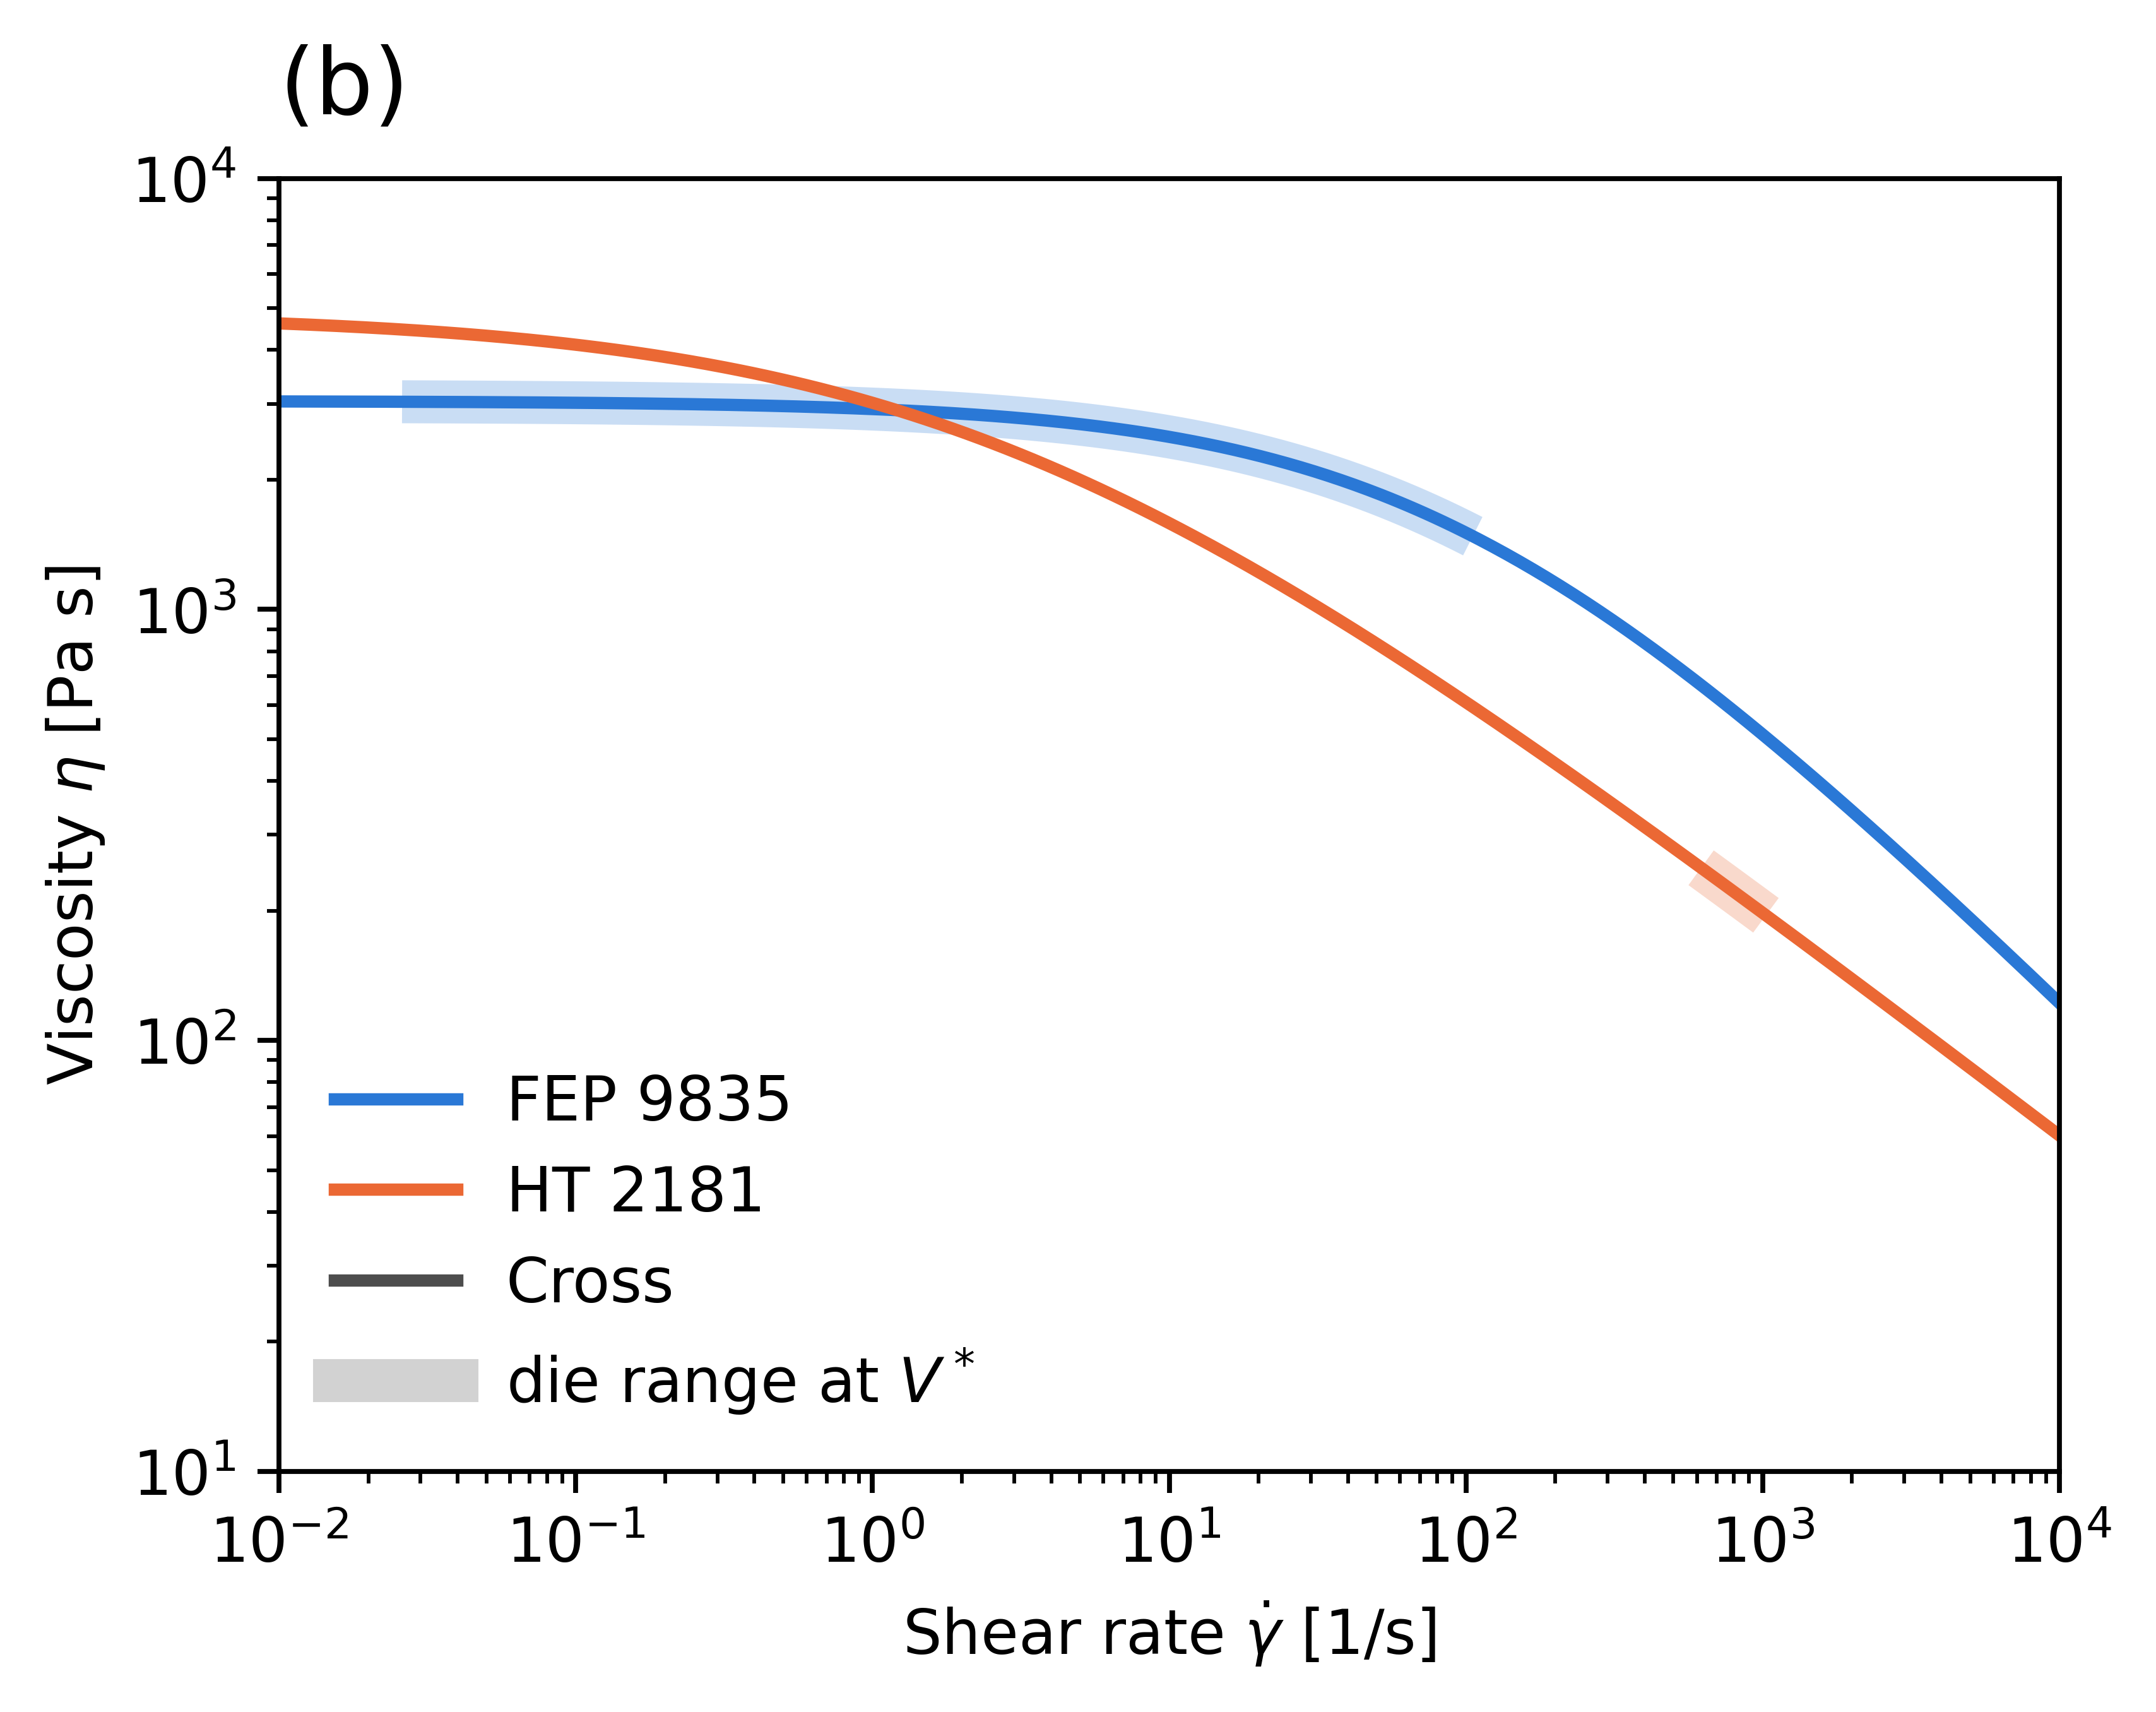

die temperature 330 °C, line speed V* = 0.05696 m/s


,η0 at T [Pa s],λ at T [s],m,die γ̇ range [1/s],η_PL / η_Cross at γ̇=1 1/s
polymer,,,,,
FEP 9835,3044,0.0103,0.685,0.026 – 105,2.615
HT 2181,4856,0.3931,0.529,620 – 1.02e+03,2.186


In [16]:
# Cross vs power law at the optimum die temperature (uses sol, prof, die, LAYER_COLORS from Section 5)
gd = np.geomspace(1e-2, 1e4, 400)
rows = []
fig, ax = plt.subplots(figsize=(5.2, 3.8), dpi=700)
for i, (layer, fluid, p) in enumerate(zip(die.layers, sol.fluids, prof)):
    g_abs = np.abs(p["gdot"])
    g_lo, g_hi = max(g_abs.min(), gd[0]), g_abs.max()
    K_pl, n_pl = fluid.equivalent_power_law(g_hi)            # power law matched at the wall shear rate
    seg = np.geomspace(g_lo, g_hi, 100)
    ax.plot(seg, fluid.viscosity(seg), "-", color=LAYER_COLORS[i], lw=7, alpha=0.25, solid_capstyle="butt")
    ax.plot(gd, fluid.viscosity(gd), "-", color=LAYER_COLORS[i], lw=2)
    # ax.plot(gd, K_pl * gd ** (n_pl - 1), "--", color=LAYER_COLORS[i], lw=1.5)
    rows.append({
        "polymer": layer.name,
        "η0 at T [Pa s]": fluid.eta0, "λ at T [s]": fluid.lam, "m": fluid.m,
        "die γ̇ range [1/s]": f"{g_abs.min():.3g} – {g_hi:.3g}",
        # "power law K [Pa s^n]": K_pl, "power law n": n_pl,
        "η_PL / η_Cross at γ̇=1 1/s": K_pl / fluid.viscosity(1.0),
    })
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(gd[0], gd[-1])
eta_all = np.concatenate([f.viscosity(gd) for f in sol.fluids])
ax.set_ylim(10 ** np.floor(np.log10(eta_all.min())), 10 ** np.ceil(np.log10(eta_all.max())))
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10.0, subs=(1.0,)))
    axis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"Shear rate $\dot\gamma$ [1/s]")
ax.set_ylabel(r"Viscosity $\eta$ [Pa s]")

# one legend: colour = polymer, line style = model
handles = [plt.Line2D([], [], color=LAYER_COLORS[i], lw=2) for i in range(die.n_layers)]
labels = [l.name for l in die.layers]
handles += [plt.Line2D([], [], color="0.3", lw=2),
            # plt.Line2D([], [], color="0.3", lw=1.5, ls="--"),
            plt.Line2D([], [], color="0.3", lw=7, alpha=0.25)]
labels += ["Cross",
           # "power law",
           r"die range at $V^*$"]
leg = ax.legend(handles, labels, loc="lower left", frameon=False)
anno = plt.annotate("(b)", (0,1.05), xycoords='axes fraction', fontsize=15)
save_fig(fig, "cross_vs_powerlaw", bbox_extra_artists=(leg, anno))
plt.show()
print(f"die temperature {T_opt - K0:.0f} °C, line speed V* = {V_opt:.5f} m/s")
pd.DataFrame(rows).set_index("polymer")

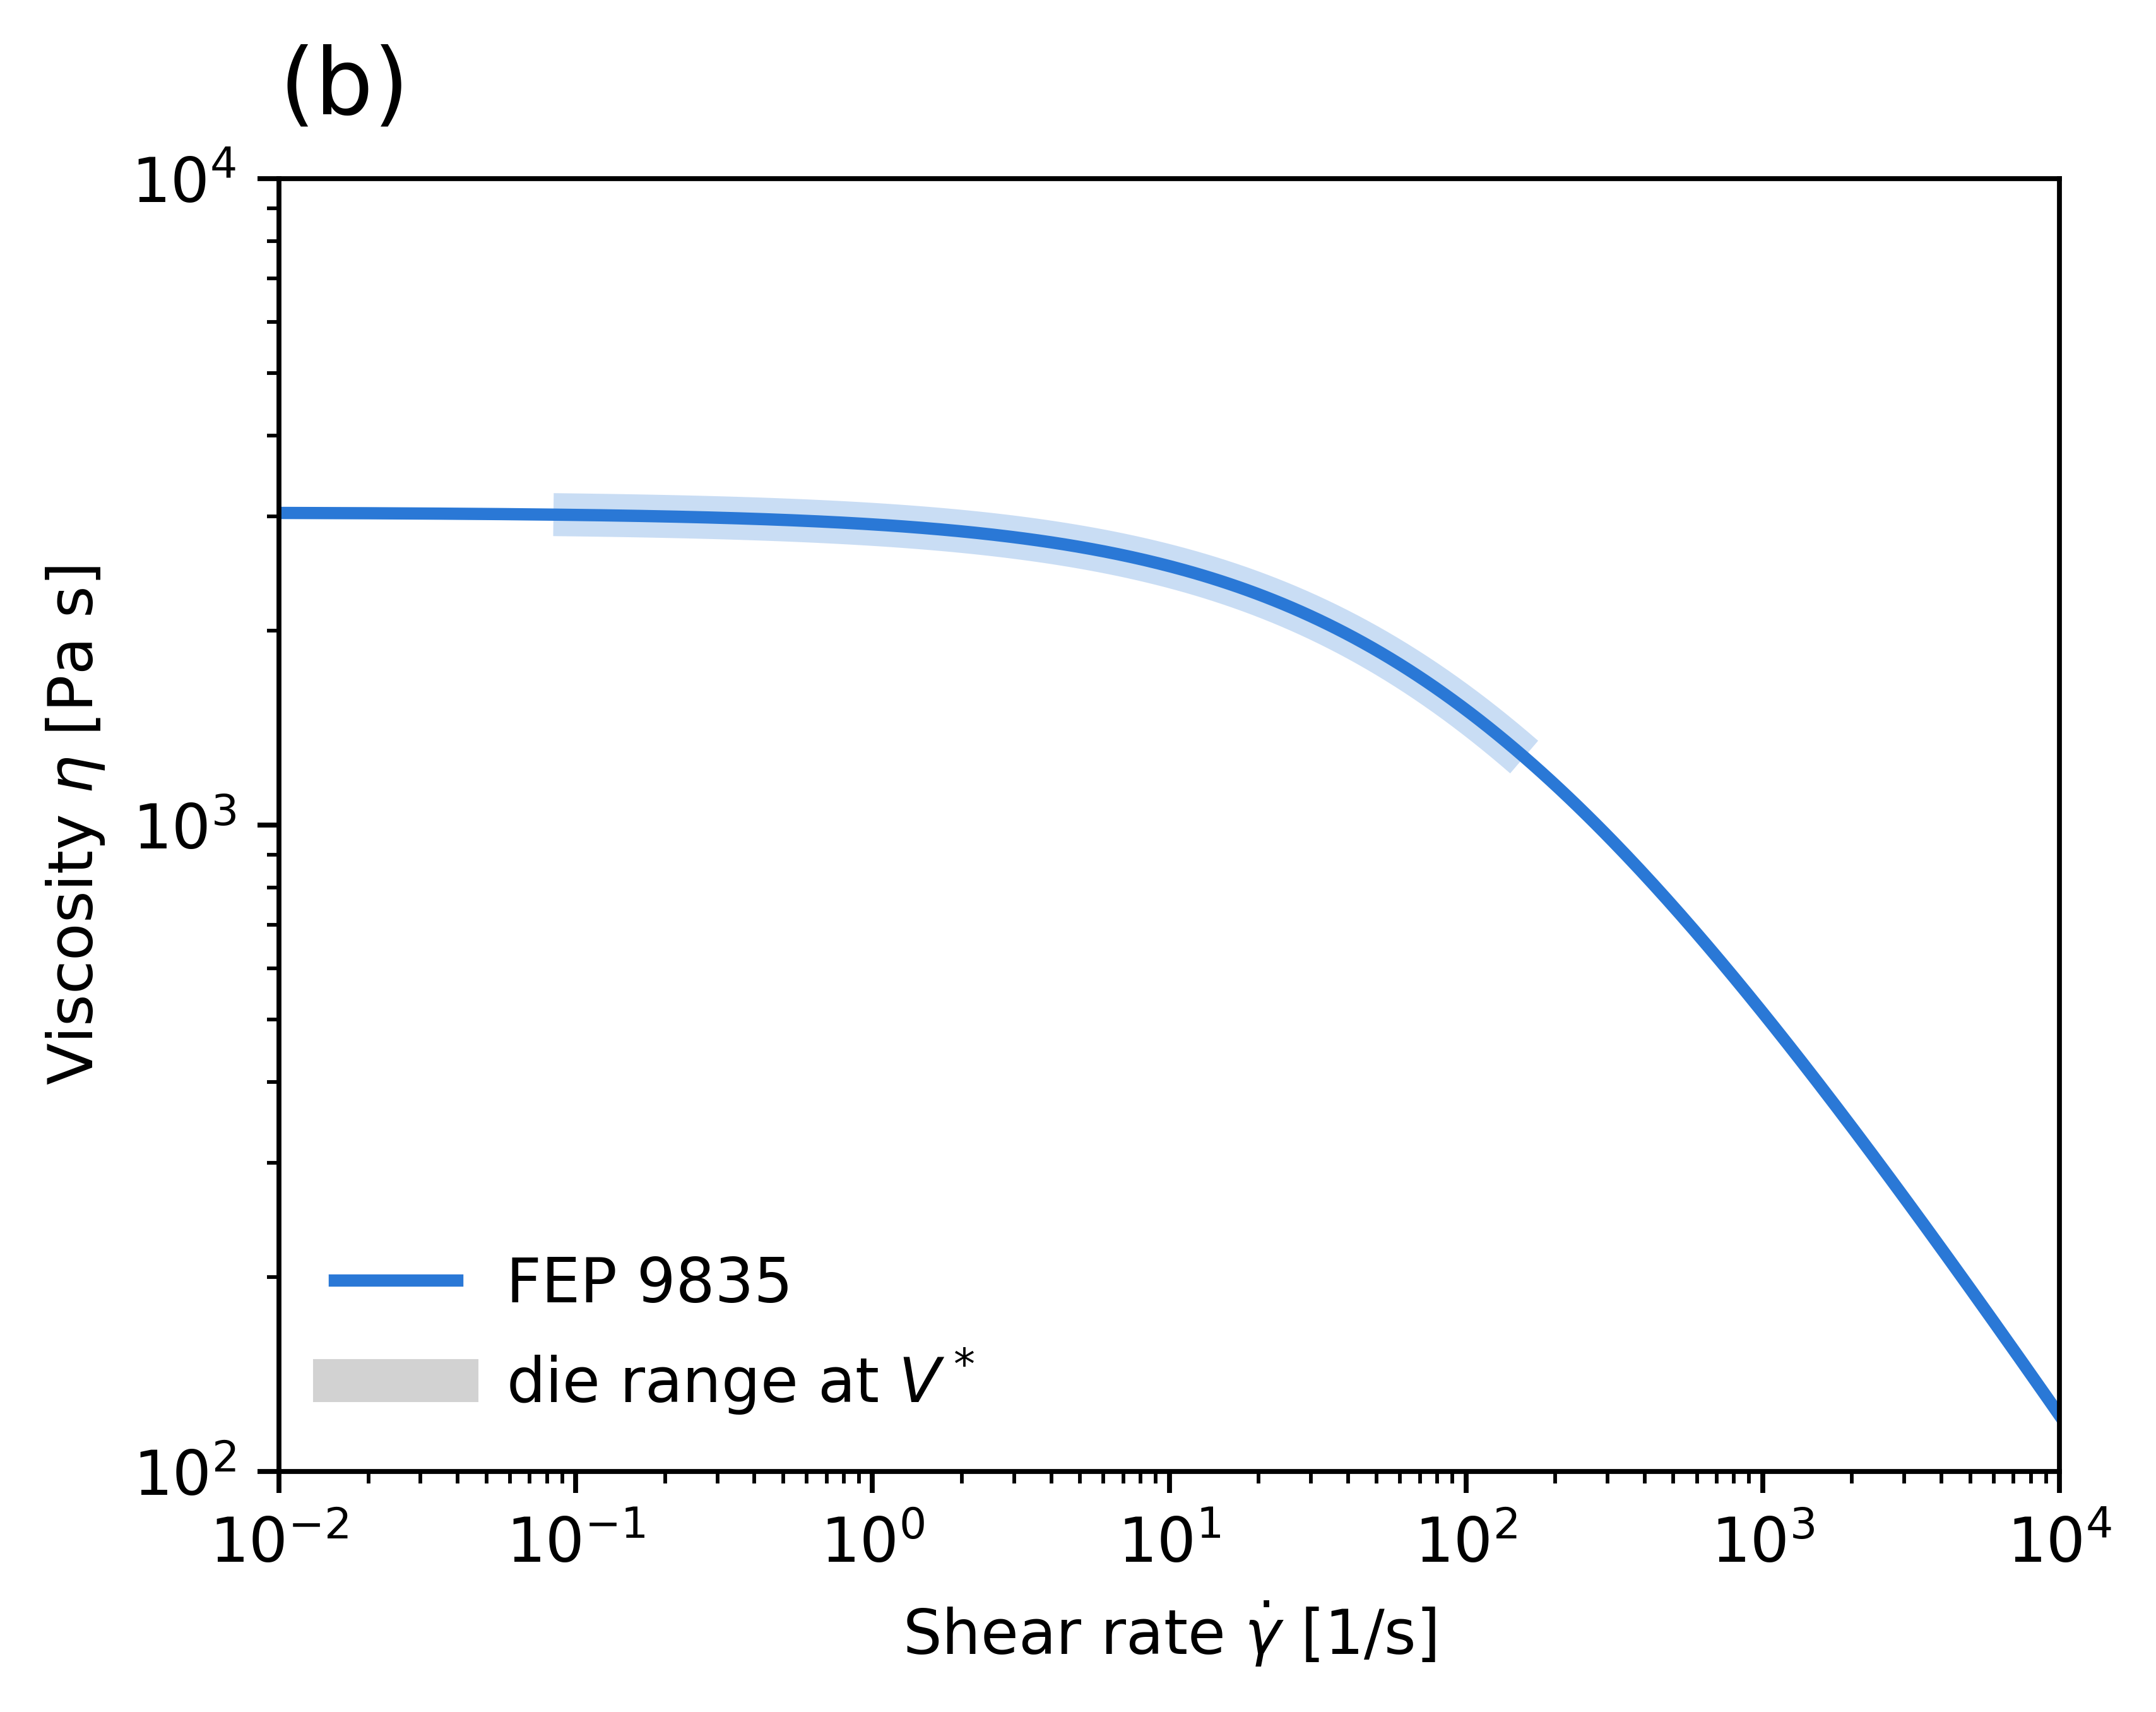

die temperature 330 °C, line speed V* = 0.01648 m/s


,η0 at T [Pa s],λ at T [s],m,die γ̇ range [1/s],η_PL / η_Cross at γ̇=1 1/s
polymer,,,,,
FEP 9835,3044,0.0103,0.685,0.0841 – 157,3.273


In [17]:
from wirecoating import LAYER_COLORS
# Cross vs power law for a single FEP layer (0.20 mm, no HT) at its own optimum die temperature
# (uses speed_limit, FEP, T_FEP_MIN, K0 and LAYER_COLORS from earlier cells)
fep_only_V = {}
for Tc in np.arange(285, 331, 5):
    fep_only_V[Tc] = speed_limit([T_FEP_MIN], Tc + K0, layers=(FEP,))[0]
T_fep_opt = max(fep_only_V, key=fep_only_V.get) + K0
V_fep, sol_fep = speed_limit([T_FEP_MIN], T_fep_opt, layers=(FEP,))
die_fep = sol_fep.die
prof_fep = die_fep.profiles(sol_fep, 300)

gd = np.geomspace(1e-2, 1e4, 400)
rows = []
fig, ax = plt.subplots(figsize=(5.2, 3.8), dpi=700)
for i, (layer, fluid, p) in enumerate(zip(die_fep.layers, sol_fep.fluids, prof_fep)):
    g_abs = np.abs(p["gdot"])
    g_lo, g_hi = max(g_abs.min(), gd[0]), g_abs.max()
    K_pl, n_pl = fluid.equivalent_power_law(g_hi)            # power law matched at the wall shear rate
    seg = np.geomspace(g_lo, g_hi, 100)
    ax.plot(seg, fluid.viscosity(seg), "-", color=LAYER_COLORS[i], lw=7, alpha=0.25, solid_capstyle="butt")
    ax.plot(gd, fluid.viscosity(gd), "-", color=LAYER_COLORS[i], lw=2)
    # ax.plot(gd, K_pl * gd ** (n_pl - 1), "--", color=LAYER_COLORS[i], lw=1.5)
    rows.append({
        "polymer": layer.name,
        "η0 at T [Pa s]": fluid.eta0, "λ at T [s]": fluid.lam, "m": fluid.m,
        "die γ̇ range [1/s]": f"{g_abs.min():.3g} – {g_hi:.3g}",
        # "power law K [Pa s^n]": K_pl, "power law n": n_pl,
        "η_PL / η_Cross at γ̇=1 1/s": K_pl / fluid.viscosity(1.0),
    })
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(gd[0], gd[-1])
eta_all = np.concatenate([f.viscosity(gd) for f in sol_fep.fluids])
ax.set_ylim(10 ** np.floor(np.log10(eta_all.min())), 10 ** np.ceil(np.log10(eta_all.max())))
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10.0, subs=(1.0,)))
    axis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"Shear rate $\dot\gamma$ [1/s]")
ax.set_ylabel(r"Viscosity $\eta$ [Pa s]")

# one legend: colour = polymer, line style = model
handles = [plt.Line2D([], [], color=LAYER_COLORS[i], lw=2) for i in range(die_fep.n_layers)]
labels = [l.name for l in die_fep.layers]
handles += [
            # plt.Line2D([], [], color="0.3", lw=1.5, ls="--"),
            plt.Line2D([], [], color="0.3", lw=7, alpha=0.25)]
labels += [
           # "power law",
           r"die range at $V^*$"]
leg = ax.legend(handles, labels, loc="lower left", frameon=False)
anno = plt.annotate("(b)", (0, 1.05), xycoords='axes fraction', fontsize=15)
save_fig(fig, "cross_vs_powerlaw_fep_only", bbox_extra_artists=(leg, anno))
plt.show()
print(f"die temperature {T_fep_opt - K0:.0f} °C, line speed V* = {V_fep:.5f} m/s")
pd.DataFrame(rows).set_index("polymer")
